In [1]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 27.9 MB/s eta 0:00:00


In [48]:
import numpy as np
import pandas as pd
import gensim.downloader
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from gensim.models import Word2Vec
from nltk.tokenize import word_tokenize

In [6]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [4]:
data = pd.read_csv('data/yelp.txt', sep='\t')
data

,Sentence,Style
0,ever since joes has changed hands it's just go...,negative
1,there is definitely not enough room in that pa...,negative
2,so basically tasted watered down.,negative
3,she said she'd be back and disappeared for a f...,negative
4,i can't believe how inconsiderate this pharmac...,negative
...,...,...
1995,"this is a fantastic location, especially becau...",positive
1996,i was pleased with their service.,positive
1997,you get so much for the price and the food is ...,positive
1998,they are so fresh and yummy.,positive


In [19]:
data['Tokens'] = data['Sentence'].apply(lambda x: word_tokenize(x.lower()))
data

,Sentence,Style,Tokens
0,ever since joes has changed hands it's just go...,negative,"[ever, since, joes, has, changed, hands, it, '..."
1,there is definitely not enough room in that pa...,negative,"[there, is, definitely, not, enough, room, in,..."
2,so basically tasted watered down.,negative,"[so, basically, tasted, watered, down, .]"
3,she said she'd be back and disappeared for a f...,negative,"[she, said, she, 'd, be, back, and, disappeare..."
4,i can't believe how inconsiderate this pharmac...,negative,"[i, ca, n't, believe, how, inconsiderate, this..."
...,...,...,...
1995,"this is a fantastic location, especially becau...",positive,"[this, is, a, fantastic, location, ,, especial..."
1996,i was pleased with their service.,positive,"[i, was, pleased, with, their, service, .]"
1997,you get so much for the price and the food is ...,positive,"[you, get, so, much, for, the, price, and, the..."
1998,they are so fresh and yummy.,positive,"[they, are, so, fresh, and, yummy, .]"


In [20]:
sentences = data['Tokens'].values.tolist()
sentences[0]

['ever',
 'since',
 'joes',
 'has',
 'changed',
 'hands',
 'it',
 "'s",
 'just',
 'gotten',
 'worse',
 'and',
 'worse',
 '.']

In [54]:
word2vec_model = Word2Vec(sentences, vector_size=50, window=3, min_count=5, sg=1)
words = word2vec_model.wv.index_to_key
word_vectors = word2vec_model.wv.vectors
print(word2vec_model.wv.index_to_key[:10])
print(len(word2vec_model.wv.index_to_key))
print(len(word2vec_model.wv.vectors))
print(len(word_vectors[0]))

['.', 'the', 'and', 'was', 'i', ',', 'a', 'is', 'to', 'it']
518
518
50


In [55]:
word_vectors[0]

array([ 0.24118422, -0.05582668, -0.03304269,  0.03897466,  0.07579356,
       -0.21291101,  0.16912153,  0.3316604 , -0.37081084, -0.19484274,
       -0.11036656, -0.28643006,  0.07777627,  0.2043434 , -0.21017475,
        0.24246688,  0.18772794, -0.01445815, -0.38680813, -0.20248698,
        0.06779647, -0.03180981,  0.30297107, -0.29967004,  0.15923971,
        0.15057369, -0.04530741,  0.18078841, -0.33327326, -0.01505976,
        0.01679365, -0.08350708,  0.05981942, -0.0102709 , -0.12883689,
        0.11370853,  0.30471092,  0.15190327,  0.03024573, -0.16305742,
        0.15593909, -0.06485309, -0.05948181,  0.00565087,  0.3654691 ,
       -0.09137793, -0.24235004, -0.06202808,  0.18566622,  0.10838652],
      dtype=float32)

In [56]:
tsne = TSNE(n_components=2)
word_vectors_2d = tsne.fit_transform(word_vectors[:50])

In [57]:
word_vectors_2d[0]

array([-12.88176  ,  -1.0050614], dtype=float32)

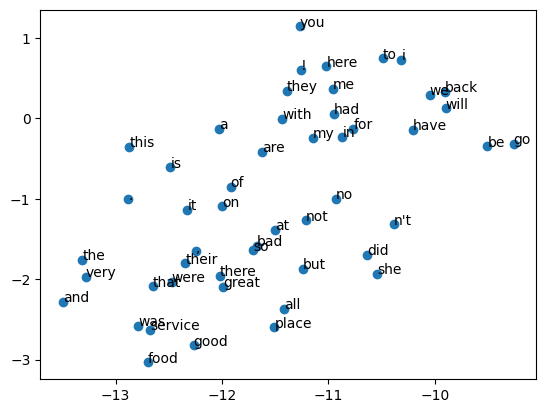

In [58]:
plt.scatter(word_vectors_2d[:, 0], word_vectors_2d[:, 1])
for label, x, y in zip(words[:50], word_vectors_2d[:, 0], word_vectors_2d[:, 1]):
    plt.annotate(label, xy=(x, y), xytext=(0, 0), textcoords='offset points')
plt.show()

In [70]:
for word in ['good', 'bad']:
    print(f'{word}: {word2vec_model.wv.most_similar(word, topn=5)}')

good: [('helpful', 0.9968368411064148), ('lunch', 0.9962143898010254), ('amazing', 0.9961574673652649), ('last', 0.996087372303009), ('day', 0.9960067868232727)]
bad: [('too', 0.9966322183609009), ('awesome', 0.9965382218360901), ('lot', 0.9963855743408203), ('not', 0.9963169097900391), ('better', 0.9963078498840332)]


In [61]:
word2vec_pretrained = gensim.downloader.load('word2vec-google-news-300')
glove_pretrained = gensim.downloader.load("glove-wiki-gigaword-100")

[==================================================] 100.0% 1662.8/1662.8MB downloaded
[==================================================] 100.0% 128.1/128.1MB downloaded


In [68]:
for word in ['good', 'bad']:
    print(f'{word}: {word2vec_pretrained.most_similar(word, topn=5)}')

good: [('great', 0.7291510105133057), ('bad', 0.7190051078796387), ('terrific', 0.6889115571975708), ('decent', 0.6837348341941833), ('nice', 0.6836092472076416)]
bad: [('good', 0.7190051674842834), ('terrible', 0.6828612089157104), ('horrible', 0.6702597737312317), ('Bad', 0.669891893863678), ('lousy', 0.6647640466690063)]


In [69]:
for word in ['good', 'bad']:
    print(f'{word}: {glove_pretrained.most_similar(word, topn=5)}')

good: [('better', 0.893191397190094), ('sure', 0.8314563035964966), ('really', 0.8297762274742126), ('kind', 0.8288268446922302), ('very', 0.8260800242424011)]
bad: [('worse', 0.7929712533950806), ('good', 0.7702797651290894), ('things', 0.7653602957725525), ('too', 0.7630148530006409), ('thing', 0.7609668374061584)]


In [64]:
print(word2vec_pretrained.most_similar(positive=['king', 'woman'], negative=['man'], topn=3))
print(word2vec_pretrained.most_similar(positive=['paris', 'italy'], negative=['france'], topn=3))
print(word2vec_pretrained.most_similar(positive=['bigger', 'cold'], negative=['big'], topn=3))
print(word2vec_pretrained.most_similar(positive=['sushi', 'germany'], negative=['japan'], topn=3))

[('queen', 0.7118193507194519), ('monarch', 0.6189674139022827), ('princess', 0.5902431011199951)]
[('lohan', 0.5069674849510193), ('madrid', 0.481842964887619), ('heidi', 0.4799900949001312)]
[('colder', 0.6777411103248596), ('warmer', 0.607578694820404), ('colder_temperatures', 0.534537136554718)]
[('gourmet_pizza', 0.5244455337524414), ('gourmet_sandwiches', 0.5183074474334717), ('currywurst', 0.5040446519851685)]


In [66]:
print(glove_pretrained.most_similar(positive=['king', 'woman'], negative=['man'], topn=3))
print(glove_pretrained.most_similar(positive=['paris', 'italy'], negative=['france'], topn=3))
print(glove_pretrained.most_similar(positive=['bigger', 'cold'], negative=['big'], topn=3))
print(glove_pretrained.most_similar(positive=['sushi', 'germany'], negative=['japan'], topn=3))

[('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]
[('rome', 0.8189547061920166), ('milan', 0.7376196980476379), ('naples', 0.7117615342140198)]
[('cooler', 0.6881814002990723), ('warmer', 0.6848933696746826), ('colder', 0.6751962304115295)]
[('gourmet', 0.5839861035346985), ('pastry', 0.5571602582931519), ('dessert', 0.5564545392990112)]
